# LangGraph 실습 

- 상태 기반 워크플로와 에이전트

## Step 01 · 환경 설정

In [1]:
import operator
import os
from typing import Annotated, Literal, TypedDict

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()
print("OpenAI:", "OK" if os.getenv("OPENAI_API_KEY") else "없음")

llm = ChatOpenAI(model="gpt-6-luna", temperature=0, reasoning={"effort": "none"})

OpenAI: OK


## Step 02 · 첫 그래프

-  State · Node · Edge

In [ ]:
# 주문 금액을 받아 할인 → 배송비 → 최종 금액을 계산하는 LLM 없는 그래프

In [2]:
class OrderState(TypedDict):
    amount: int          # 주문 금액
    grade: str           # 회원 등급
    discount: int
    shipping: int
    total: int

In [3]:
def apply_discount(state: OrderState) -> dict:
    rate = {"vip": 0.1, "gold": 0.05}.get(state["grade"], 0)
    return {"discount": int(state["amount"] * rate)}          # 바꿀 키만 반환

def add_shipping(state: OrderState) -> dict:
    paid = state["amount"] - state["discount"]
    return {"shipping": 0 if paid >= 50_000 else 3_000}

def summarize(state: OrderState) -> dict:
    return {"total": state["amount"] - state["discount"] + state["shipping"]}

In [4]:
from langgraph.graph import END, START, StateGraph

builder = StateGraph(OrderState)
builder.add_node("discount", apply_discount)
builder.add_node("shipping", add_shipping)
builder.add_node("summary", summarize)

builder.add_edge(START, "discount")
builder.add_edge("discount", "shipping")
builder.add_edge("shipping", "summary")
builder.add_edge("summary", END)
order_graph = builder.compile()

In [5]:
print(order_graph.invoke({"amount": 52_000, "grade": "gold"}))

{'amount': 52000, 'grade': 'gold', 'discount': 2600, 'shipping': 3000, 'total': 52400}


In [6]:
print(order_graph.invoke({"amount": 30_000, "grade": "basic"}))

{'amount': 30000, 'grade': 'basic', 'discount': 0, 'shipping': 3000, 'total': 33000}


In [ ]:
# 그래프 구조 확인 — Mermaid 텍스트 (https://mermaid.live 에 붙여 넣으면 그림으로 확인)
print(order_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	discount(discount)
	shipping(shipping)
	summary(summary)
	__end__([<p>__end__</p>]):::last
	__start__ --> discount;
	discount --> shipping;
	shipping --> summary;
	summary --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



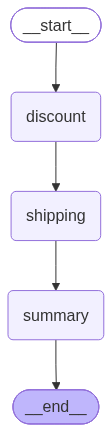

In [9]:
# Jupyter에서는 이미지로 바로 표시
from IPython.display import Image, display
display(Image(order_graph.get_graph().draw_mermaid_png()))

## Step 03 · State와 Reducer

In [ ]:
# 같은 키를 여러 노드가 갱신할 때, 값을 **덮어쓸지 · 누적할지**를 Reducer가 정한다.

In [10]:
class LogState(TypedDict):
    status: str                                  # Reducer 없음 → 덮어쓰기
    logs: Annotated[list[str], operator.add]     # operator.add → 리스트 누적

In [11]:
def step_a(state: LogState):
    return {"status": "A 완료", "logs": ["A 실행"]}

def step_b(state: LogState):
    return {"status": "B 완료", "logs": ["B 실행"]}

In [12]:
g = StateGraph(LogState)
g.add_node("a", step_a)
g.add_node("b", step_b)
g.add_edge(START, "a")
g.add_edge("a", "b")
g.add_edge("b", END)
print(g.compile().invoke({"status": "시작", "logs": ["입력"]}))
# >> {'status': 'B 완료', 'logs': ['입력', 'A 실행', 'B 실행']}

{'status': 'B 완료', 'logs': ['입력', 'A 실행', 'B 실행']}


In [13]:
# add_messages — 메시지 누적 + 같은 id면 교체, dict/튜플도 메시지로 변환
from langchain_core.messages import AIMessage, HumanMessage
from langgraph.graph.message import add_messages

old = [HumanMessage("안녕", id="1"), AIMessage("반가워요", id="2")]
print(add_messages(old, [("user", "날씨 알려줘")]))                 # 추가
print(add_messages(old, [AIMessage("반갑습니다!", id="2")])[-1])     # 같은 id → 교체

[HumanMessage(content='안녕', additional_kwargs={}, response_metadata={}, id='1'), AIMessage(content='반가워요', additional_kwargs={}, response_metadata={}, id='2', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='날씨 알려줘', additional_kwargs={}, response_metadata={}, id='eae139f4-43a2-496d-9583-5e3db2493e17')]
content='반갑습니다!' additional_kwargs={} response_metadata={} id='2' tool_calls=[] invalid_tool_calls=[]


In [14]:
# MessagesState — messages 키(add_messages)가 미리 정의된 State. 필드를 추가해 확장한다.
from langgraph.graph import MessagesState

class ChatState(MessagesState):
    user_name: str

In [15]:
def chatbot(state: ChatState):
    system = ("system", f"사용자 이름은 {state['user_name']}입니다. 이름을 불러 주며 짧게 답하세요.")
    return {"messages": [llm.invoke([system] + state["messages"])]}

In [16]:
chat_graph = (
    StateGraph(ChatState)
    .add_node("chatbot", chatbot)
    .add_edge(START, "chatbot")
    .add_edge("chatbot", END)
    .compile()
)

In [17]:
out = chat_graph.invoke({"messages": [("user", "LangGraph를 한 문장으로 설명해줘")], "user_name": "지수"})
for m in out["messages"]:
    print(f"[{m.type}] {m.content}")

[human] LangGraph를 한 문장으로 설명해줘
[ai] [{'type': 'text', 'text': '지수님, LangGraph는 여러 단계의 AI 작업 흐름을 그래프 형태로 구성하고 관리하는 프레임워크입니다.', 'annotations': [], 'id': 'msg_08238c26012147e5006ae3ee4c71ac87d2ae80e566dbc59c96', 'phase': 'final_answer'}]


## Step 04 · 조건부 엣지와 루프

In [18]:
# (1) LLM 분류 결과로 분기 — 고객 문의 라우터
from pydantic import BaseModel, Field

class Route(BaseModel):
    category: Literal["refund", "delivery", "other"] = Field(description="문의 유형")

class InquiryState(TypedDict):
    question: str
    category: str
    answer: str

In [20]:
classifier = llm.with_structured_output(Route)

def classify(state: InquiryState):
    r = classifier.invoke(f"고객 문의를 refund / delivery / other 중 하나로 분류하세요.\n문의: {state['question']}")
    return {"category": r.category}

def refund_node(state: InquiryState):
    return {"answer": "환불은 수령 후 7일 이내 마이페이지 > 주문 내역에서 신청할 수 있습니다."}

def delivery_node(state: InquiryState):
    return {"answer": "배송 조회는 주문 내역의 송장 번호로 확인할 수 있습니다."}

def other_node(state: InquiryState):
    return {"answer": llm.invoke(f"쇼핑몰 상담원으로서 두 문장으로 답하세요: {state['question']}").content}

def route_by_category(state: InquiryState) -> Literal["refund", "delivery", "other"]:
    return state["category"]

In [21]:
b = StateGraph(InquiryState)

b.add_node("classify", classify)
b.add_node("refund", refund_node)
b.add_node("delivery", delivery_node)
b.add_node("other", other_node)

b.add_edge(START, "classify")

b.add_conditional_edges("classify", route_by_category)   # 반환값 = 다음 노드 이름
for n in ["refund", "delivery", "other"]:
    b.add_edge(n, END)
router = b.compile()

In [22]:
for q in ["어제 받은 신발 환불하고 싶어요", "택배가 아직 안 왔어요", "포인트는 언제 적립돼요?"]:
    r = router.invoke({"question": q})
    print(f"[{r['category']}] {q} → {r['answer']}")

[refund] 어제 받은 신발 환불하고 싶어요 → 환불은 수령 후 7일 이내 마이페이지 > 주문 내역에서 신청할 수 있습니다.
[delivery] 택배가 아직 안 왔어요 → 배송 조회는 주문 내역의 송장 번호로 확인할 수 있습니다.
[other] 포인트는 언제 적립돼요? → [{'type': 'text', 'text': '포인트는 주문하신 상품이 배송 완료된 후 적립됩니다. 적립까지는 보통 며칠 정도 걸릴 수 있으며, 자세한 일정은 주문 내역에서 확인해 주세요.', 'annotations': [], 'id': 'msg_0f112f4ed17d7a73006ae3f0be2b0887d2a4ea705fa4be8b34', 'phase': 'final_answer'}]


In [ ]:
# (2) 루프 — 작성 → 검토 → (기준 미달이면) 재작성, 최대 3회
class Review(BaseModel):
    score: int = Field(description="1~10점")
    feedback: str = Field(description="개선할 점 한 문장")

class WriteState(TypedDict):
    topic: str
    draft: str
    score: int
    feedback: str
    # revision: int
    revision: Annotated[int, operator.add]

In [28]:
def write(state: WriteState):
    fb = f"\n이전 피드백: {state['feedback']}" if state.get("feedback") else ""
    draft = llm.invoke(f"'{state['topic']}' 제품 소개 문구를 40자 이내로 작성하세요.{fb}").content
    # return {"draft": draft, "revision": state.get("revision", 0) + 1}
    return {"draft": draft, "revision": 1}

def review(state: WriteState):
    r = llm.with_structured_output(Review).invoke(
        f"다음 광고 문구를 명확성 · 구체성 기준으로 채점하세요.\n문구: {state['draft']}")
    return {"score": r.score, "feedback": r.feedback}

def should_rewrite(state: WriteState) -> Literal["write", "__end__"]:
    if state["score"] >= 8 or state["revision"] >= 3:
        return END
    return "write"

In [29]:
wb = StateGraph(WriteState)
wb.add_node("write", write)
wb.add_node("review", review)

wb.add_edge(START, "write")
wb.add_edge("write", "review")
wb.add_conditional_edges("review", should_rewrite)     # review → write 로 되돌아가는 사이클

writer_graph = wb.compile()

In [30]:
for step in writer_graph.stream({"topic": "접이식 전기 자전거"}, stream_mode="updates"):
    for node, upd in step.items():
        print(node, "→", upd)

write → {'draft': [{'type': 'text', 'text': '가볍게 접어 보관하고, 전기로 편하게 달리는 접이식 자전거', 'annotations': [], 'id': 'msg_001e3365e5193bbb006ae3f27295f487d2af1f3b24812c8ace', 'phase': 'final_answer'}], 'revision': 1}
review → {'score': 6, 'feedback': '접이식·전기 구동이라는 특징은 드러나지만, 무게나 보관 편의성, 주행 성능을 뒷받침하는 구체적인 정보가 없어 다소 추상적입니다.'}
write → {'draft': [{'type': 'text', 'text': '접어 보관하기 편하고, 전기 구동으로 언덕길도 가볍게 달리는 자전거 \n', 'annotations': [], 'id': 'msg_0fd09c0a05019280006ae3f276e78087d2975dc64239dca8e8', 'phase': 'final_answer'}], 'revision': 1}
review → {'score': 5, 'feedback': '접이식 보관과 전기 구동이라는 장점은 드러나지만, 크기·무게나 주행 성능 등 구체적인 정보가 없어 표현이 다소 모호합니다.'}
write → {'draft': [{'type': 'text', 'text': '접어 보관하기 편하고 전기 구동으로 가볍게 달리는 자전거입니다.', 'annotations': [], 'id': 'msg_06a11f0e5c4073d1006ae3f27ee15087d2aa96dbca7b065105', 'phase': 'final_answer'}], 'revision': 1}
review → {'score': 5, 'feedback': '접이식과 전기 구동이라는 특징은 알 수 있지만, 주행 성능이나 보관 편의성을 뒷받침하는 구체적인 수치·조건이 없어 다소 모호합니다.'}


In [31]:
r = writer_graph.invoke({"topic": "접이식 전기 자전거"})
r

{'topic': '접이식 전기 자전거',
 'draft': [{'type': 'text',
   'text': '접어 보관·이동이 간편한 전기 자전거, 출퇴근과 근거리 주행에 편리합니다.',
   'annotations': [],
   'id': 'msg_02cab25599e42aae006ae3f3175e9887d281c6966bf04e0651',
   'phase': 'final_answer'}],
 'score': 6,
 'feedback': '접이식이라는 장점과 사용 상황은 명확하지만, 무게·접었을 때 크기·주행거리 등 편리함을 뒷받침할 구체적인 정보가 부족합니다.',
 'revision': 3}

## Step 05 · Command · Send

In [32]:
# Command — 상태 갱신(update)과 다음 노드 이동(goto)을 노드 안에서 한 번에
from langgraph.types import Command

class TicketState(TypedDict):
    text: str
    priority: str
    handled_by: str

In [33]:
def triage(state: TicketState) -> Command[Literal["urgent_team", "normal_team"]]:
    urgent = any(k in state["text"] for k in ["장애", "결제 실패", "접속 불가"])
    return Command(
        update={"priority": "high" if urgent else "normal"},
        goto="urgent_team" if urgent else "normal_team",
    )

def urgent_team(state: TicketState):
    return {"handled_by": "온콜 엔지니어"}

def normal_team(state: TicketState):
    return {"handled_by": "고객지원팀"}

In [34]:
tb = StateGraph(TicketState)
tb.add_node("triage", triage)          # 조건부 엣지 없이 Command로 이동
tb.add_node("urgent_team", urgent_team)
tb.add_node("normal_team", normal_team)

tb.add_edge(START, "triage")
tb.add_edge("urgent_team", END)
tb.add_edge("normal_team", END)
ticket_graph = tb.compile()

In [35]:
print(ticket_graph.invoke({"text": "결제 실패가 계속 발생합니다"}))

{'text': '결제 실패가 계속 발생합니다', 'priority': 'high', 'handled_by': '온콜 엔지니어'}


In [36]:
print(ticket_graph.invoke({"text": "영수증 재발급 부탁드려요"}))

{'text': '영수증 재발급 부탁드려요', 'priority': 'normal', 'handled_by': '고객지원팀'}


In [37]:
# Send — 리스트 원소마다 같은 노드를 병렬 실행하고(Map) 결과를 모은다(Reduce)
from langgraph.types import Send

class ReviewsState(TypedDict):
    reviews: list[str]
    summaries: Annotated[list[str], operator.add]   # 병렬 결과를 누적
    report: str

class OneReview(TypedDict):
    review: str

In [ ]:
def fan_out(state: ReviewsState):
    return [Send("summarize_one", {"review": r}) for r in state["reviews"]]

def summarize_one(state: OneReview):
    s = llm.invoke(f"다음 리뷰의 핵심을 10자 이내로 요약: {state['review']}").content
    return {"summaries": [s]}

def make_report(state: ReviewsState):
    joined = "\n".join(f"- {s}" for s in state["summaries"])
    return {"report": llm.invoke(f"다음 리뷰 요약들을 보고 개선점 1가지를 제안하세요.\n{joined}").content}

In [40]:
mb = StateGraph(ReviewsState)
mb.add_node("summarize_one", summarize_one)
mb.add_node("report", make_report)

mb.add_conditional_edges(START, fan_out, ["summarize_one"])
mb.add_edge("summarize_one", "report")
mb.add_edge("report", END)
mr_graph = mb.compile()

In [41]:
res = mr_graph.invoke({"reviews": ["배송이 빨라요", "사이즈가 작게 나와요", "색이 사진과 달라요", "가성비 최고"]})
print(res["summaries"])
print(res["report"])

호출됨?호출됨?

호출됨?
호출됨?
[[{'type': 'text', 'text': '빠른 배송', 'annotations': [], 'id': 'msg_0dfa565c3460d036006ae3f5e76a4887d281d5d58023dddb87', 'phase': 'final_answer'}], [{'type': 'text', 'text': '작게 나옴', 'annotations': [], 'id': 'msg_00fc2e1fa4ebbeb3006ae3f5e7c53c87d280867fd39e6b8e9d', 'phase': 'final_answer'}], [{'type': 'text', 'text': '색상 차이', 'annotations': [], 'id': 'msg_04b69820beaad9c4006ae3f5e7848c87d2a356fc988b642b9e', 'phase': 'final_answer'}], [{'type': 'text', 'text': '가성비 최고', 'annotations': [], 'id': 'msg_0b6ac972c0d955f7006ae3f5e79ebc87d289da7139c896916b', 'phase': 'final_answer'}]]
[{'type': 'text', 'text': '사이즈가 작게 나온다는 의견이 있으므로, 상세 페이지에 실측 사이즈와 사이즈 선택 가이드를 제공하세요.', 'annotations': [], 'id': 'msg_0712426c84c8df44006ae3f5e9744887d2aa0fd365d28c2942', 'phase': 'final_answer'}]


## Step 06 · 도구 에이전트

- ToolNode · tools_condition

In [ ]:
# `create_agent`가 내부에서 만드는 에이전트 루프를 그래프로 직접 구성한다.

In [43]:
from langchain.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition

STOCK = {"러닝화": 12, "요가매트": 0, "텀블러": 40}

@tool
def check_stock(product: str) -> str:
    """상품명의 재고 수량을 조회합니다."""
    return f"{product} 재고: {STOCK.get(product, '없는 상품')}"

@tool
def restock_date(product: str) -> str:
    """품절 상품의 재입고 예정일을 조회합니다."""
    return {"요가매트": "10월 15일"}.get(product, "재입고 계획 없음")

In [44]:
tools = [check_stock, restock_date]
llm_with_tools = llm.bind_tools(tools)

In [45]:
def agent(state: MessagesState):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

In [46]:
ab = StateGraph(MessagesState)
ab.add_node("agent", agent)
ab.add_node("tools", ToolNode(tools))

ab.add_edge(START, "agent")
ab.add_conditional_edges("agent", tools_condition)   # tool_calls 있으면 "tools", 없으면 END
ab.add_edge("tools", "agent")

tool_agent = ab.compile()

In [47]:
out = tool_agent.invoke({"messages": [("user", "요가매트 재고 있어? 없으면 언제 들어와?")]})
for m in out["messages"]:
    print(f"[{m.type}]", m.content or m.tool_calls)

[human] 요가매트 재고 있어? 없으면 언제 들어와?
[ai] [{'arguments': '{"product":"요가매트"}', 'call_id': 'call_8lmqhjvJnfN3NQbFJU11lwzW', 'name': 'check_stock', 'type': 'function_call', 'id': 'fc_073efd88ad01b40b006ae3fac5677487d2ad8ce53ca8e3b7c4', 'status': 'completed'}]
[tool] 요가매트 재고: 0
[ai] [{'arguments': '{"product":"요가매트"}', 'call_id': 'call_SLWZj63vnmqp056swqj46f1v', 'name': 'restock_date', 'type': 'function_call', 'id': 'fc_073efd88ad01b40b006ae3fac8948887d2b84c9482539124bc', 'status': 'completed'}]
[tool] 10월 15일
[ai] [{'type': 'text', 'text': '현재 요가매트는 재고가 없습니다. 10월 15일에 재입고될 예정입니다.', 'annotations': [], 'id': 'msg_073efd88ad01b40b006ae3facaa2ac87d2aa488a5faccacc99', 'phase': 'final_answer'}]


## Step 07 · Persistence · Human-in-the-Loop

In [48]:
from langgraph.checkpoint.memory import InMemorySaver

memory = InMemorySaver()
mem_agent = ab.compile(checkpointer=memory)

cfg = {"configurable": {"thread_id": "user-1"}}
mem_agent.invoke({"messages": [("user", "텀블러 재고 알려줘")]}, cfg)
out = mem_agent.invoke({"messages": [("user", "방금 물어본 상품 이름이 뭐였지?")]}, cfg)
print(out["messages"][-1].content)

[{'type': 'text', 'text': '텀블러였어요.', 'annotations': [], 'id': 'msg_0a33f26db91e2c62006ae3fd7608fc87d28fb348569a4a0d56', 'phase': 'final_answer'}]


In [49]:
other = {"configurable": {"thread_id": "user-2"}}
print(mem_agent.invoke({"messages": [("user", "방금 물어본 상품 이름이 뭐였지?")]}, other)["messages"][-1].content)

[{'type': 'text', 'text': '이 대화에서는 아직 상품명을 말씀해 주시지 않았어요.', 'annotations': [], 'id': 'msg_0e4f6eefac128933006ae3fd7ad13087d28c24de0ac70f627f', 'phase': 'final_answer'}]


In [54]:
for h in mem_agent.get_state_history(cfg):
    print(h)

StateSnapshot(values={'messages': [HumanMessage(content='텀블러 재고 알려줘', additional_kwargs={}, response_metadata={}, id='22d8bafa-de67-45fd-8480-bede0a7d39d0'), AIMessage(content=[{'arguments': '{"product":"텀블러"}', 'call_id': 'call_lpLe5Xjvbz6B1VLJfVDytFUn', 'name': 'check_stock', 'type': 'function_call', 'id': 'fc_0a33f26db91e2c62006ae3fd7168b087d28836d525e12ac36f', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_0a33f26db91e2c62006ae3fd70a1a887d2894363c06cce9ac6', 'created_at': 1793326448.0, 'metadata': {}, 'model': 'gpt-6-luna', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-6-luna'}, id='resp_0a33f26db91e2c62006ae3fd70a1a887d2894363c06cce9ac6', tool_calls=[{'name': 'check_stock', 'args': {'product': '텀블러'}, 'id': 'call_lpLe5Xjvbz6B1VLJfVDytFUn', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 82, 'output_tokens': 21, 'total_tokens': 103, 'input_token_deta

In [55]:
# 저장된 상태 조회 · 체크포인트 이력
snap = mem_agent.get_state(cfg)
print("메시지 수:", len(snap.values["messages"]), "| 다음 노드:", snap.next)

메시지 수: 6 | 다음 노드: ()


In [56]:
history = list(mem_agent.get_state_history(cfg))
for h in history[:6]:
    print(f"step={h.metadata['step']:>2}  next={h.next}  msgs={len(h.values.get('messages', []))}")

step= 6  next=()  msgs=6
step= 5  next=('agent',)  msgs=5
step= 4  next=('__start__',)  msgs=4
step= 3  next=()  msgs=4
step= 2  next=('agent',)  msgs=3
step= 1  next=('tools',)  msgs=2


In [57]:
# Time Travel — 과거 체크포인트에서 다른 질문으로 다시 실행 (새 분기 생성)
first_turn_end = [h for h in history if not h.next][-1]   # 이력은 최신순 → 가장 오래된 "완료" 시점 = 첫 대화 종료
print("분기 시점 step:", first_turn_end.metadata["step"], "| 메시지 수:", len(first_turn_end.values["messages"]))

분기 시점 step: 3 | 메시지 수: 4


In [58]:
branch = mem_agent.invoke({"messages": [("user", "러닝화 재고는?")]}, first_turn_end.config)
print(branch["messages"][-1].content)

[{'type': 'text', 'text': '러닝화 재고는 12개입니다.', 'annotations': [], 'id': 'msg_0a33f26db91e2c62006ae3fe5a673c87d280c33f1d2ddb234c', 'phase': 'final_answer'}]


In [59]:
# interrupt — 노드 실행 중 멈추고 사람의 결정을 받아 재개
from langgraph.types import interrupt

class RefundState(TypedDict):
    order_id: str
    amount: int
    approved: bool
    result: str

In [60]:
def request_approval(state: RefundState):
    if state["amount"] < 100_000:                 # 소액은 자동 승인
        return {"approved": True}
    decision = interrupt({"question": "고액 환불 승인할까요?", "order_id": state["order_id"],
                          "amount": state["amount"]})
    return {"approved": decision == "approve"}

def execute(state: RefundState):
    return {"result": f"{state['order_id']} 환불 {'완료' if state['approved'] else '거절'}"}

In [62]:
hb = StateGraph(RefundState)
hb.add_node("approval", request_approval)
hb.add_node("execute", execute)
hb.add_edge(START, "approval")
hb.add_edge("approval", "execute")
hb.add_edge("execute", END)
hitl = hb.compile(checkpointer=InMemorySaver())    # interrupt에는 checkpointer 필수

c = {"configurable": {"thread_id": "refund-77"}}
first = hitl.invoke({"order_id": "A-77", "amount": 250_000}, c)
print("중단:", first["__interrupt__"][0].value)
print("다음 노드:", hitl.get_state(c).next)

중단: {'question': '고액 환불 승인할까요?', 'order_id': 'A-77', 'amount': 250000}
다음 노드: ('approval',)


In [69]:
c = {"configurable": {"thread_id": "refund-80"}}
first = hitl.invoke({"order_id": "A-80", "amount": 150_000}, c)

In [70]:
first['__interrupt__'][0]

Interrupt(value={'question': '고액 환불 승인할까요?', 'order_id': 'A-80', 'amount': 150000}, id='e4978a7d32f5bfe4de5d2a08d1b0c4c0', response_schema=None)

In [ ]:
final = hitl.invoke(Command(resume="approve"), c)   # 사람의 결정으로 재개
print(final["result"])

A-80 환불 거절


## Step 08 · Streaming · Subgraph

In [72]:
# stream_mode 비교
q = {"messages": [("user", "러닝화 재고 알려줘")]}

print("--- updates: 노드별 변경분")
for chunk in tool_agent.stream(q, stream_mode="updates"):
    print(list(chunk.keys()))

--- updates: 노드별 변경분
['agent']
['tools']
['agent']


In [73]:
print("--- values: 매 단계 전체 상태")
for chunk in tool_agent.stream(q, stream_mode="values"):
    print(len(chunk["messages"]), "개 메시지")

--- values: 매 단계 전체 상태
1 개 메시지
2 개 메시지
3 개 메시지
4 개 메시지


In [74]:
print("--- messages: LLM 토큰")
for token, meta in tool_agent.stream({"messages": [("user", "LangGraph 장점 한 줄")]}, stream_mode="messages"):
    if token.content and meta["langgraph_node"] == "agent":
        print(token.content, end="", flush=True)

--- messages: LLM 토큰
[{'type': 'text', 'text': '', 'phase': 'final_answer', 'index': 0}][{'type': 'text', 'text': 'Lang', 'index': 0}][{'type': 'text', 'text': 'Graph', 'index': 0}][{'type': 'text', 'text': '는', 'index': 0}][{'type': 'text', 'text': ' 복', 'index': 0}][{'type': 'text', 'text': '잡', 'index': 0}][{'type': 'text', 'text': '한', 'index': 0}][{'type': 'text', 'text': ' AI', 'index': 0}][{'type': 'text', 'text': ' 워', 'index': 0}][{'type': 'text', 'text': '크', 'index': 0}][{'type': 'text', 'text': '플', 'index': 0}][{'type': 'text', 'text': '로', 'index': 0}][{'type': 'text', 'text': '를', 'index': 0}][{'type': 'text', 'text': ' 상태', 'index': 0}][{'type': 'text', 'text': '와', 'index': 0}][{'type': 'text', 'text': ' 흐', 'index': 0}][{'type': 'text', 'text': '름', 'index': 0}][{'type': 'text', 'text': ' 중심', 'index': 0}][{'type': 'text', 'text': '으로', 'index': 0}][{'type': 'text', 'text': ' 구성', 'index': 0}][{'type': 'text', 'text': '해', 'index': 0}][{'type': 'text', 'text': ' 제', '

In [75]:
# custom — 노드 안에서 진행 상황을 직접 보내기
from langgraph.config import get_stream_writer

class JobState(TypedDict):
    files: list[str]
    done: int

In [76]:
def process(state: JobState):
    writer = get_stream_writer()
    for i, f in enumerate(state["files"], 1):
        writer({"progress": f"{i}/{len(state['files'])} {f} 처리 중"})
    return {"done": len(state["files"])}

In [77]:
job = StateGraph(JobState).add_node("process", process).add_edge(START, "process").compile()

In [78]:
for mode, chunk in job.stream({"files": ["a.pdf", "b.pdf", "c.pdf"]}, stream_mode=["custom", "updates"]):
    print(mode, chunk)

custom {'progress': '1/3 a.pdf 처리 중'}
custom {'progress': '2/3 b.pdf 처리 중'}
custom {'progress': '3/3 c.pdf 처리 중'}
updates {'process': {'done': 3}}


In [79]:
# Subgraph — 컴파일한 그래프를 다른 그래프의 노드로 사용 (State 키를 공유)
class PipelineState(TypedDict):
    question: str
    category: str
    answer: str
    polished: str

In [80]:
def polish(state: PipelineState):
    return {"polished": llm.invoke(f"다음 답변을 공손한 존댓말 한 문장으로 다듬으세요: {state['answer']}").content}

In [81]:
pb = StateGraph(PipelineState)
pb.add_node("route", router)          # Step 04의 문의 라우터 그래프를 노드로
pb.add_node("polish", polish)
pb.add_edge(START, "route")
pb.add_edge("route", "polish")
pb.add_edge("polish", END)
pipeline = pb.compile()

In [82]:
for ns, chunk in pipeline.stream({"question": "환불 어떻게 해요?"}, stream_mode="updates", subgraphs=True):
    print(ns or "(parent)", list(chunk.keys()))
print(pipeline.invoke({"question": "환불 어떻게 해요?"})["polished"])

('route:df46de99-8736-5f41-7484-16e831b3982c',) ['classify']
('route:df46de99-8736-5f41-7484-16e831b3982c',) ['refund']
(parent) ['route']
(parent) ['polish']
[{'type': 'text', 'text': '환불은 상품 수령 후 7일 이내에 마이페이지의 ‘주문 내역’에서 신청하실 수 있습니다.', 'annotations': [], 'id': 'msg_0cf2954d4c62ffea006ae4027218e087d2a30a2fd5224e847d', 'phase': 'final_answer'}]
